# LSTM v3: balanced anomaly-aware workload forecasting

**Goal:** test whether a better-trained, regularized LSTM with anomaly context can reduce *overall* MSE/MAE without giving up the spike protection seen in the previous run.

This notebook is an experiment, not a guaranteed improvement. A more complex network can perform worse. The test split is kept untouched for final evaluation; all model/configuration selection happens on validation data.

## What is new
1. **Train-only feature and target standardization** to make optimization better conditioned without leaking test statistics.
2. **Residual causal-convolution + BiLSTM + temporal attention** candidate. The bidirectional layer only sees the already-observed 288-step input window, not future samples.
3. **Regularization and learning-rate reduction**: dropout, layer normalization, Adam, ReduceLROnPlateau and early stopping.
4. **Balanced objectives**: ordinary MSE, Huber, and *mild* spike-aware asymmetric losses. The primary selection metric remains validation point MSE, with MAE and spike metrics reported alongside it.
5. **Ablations**: raw inputs, anomaly scores, anomaly flags, and scores+flags.
6. **Validation-only screening followed by a locked test evaluation** on all 11 traces and 3 seeds.

The notebook preserves the project's 288-step lookback and 2-step target offset, and expects the same `*_flags.csv` anomaly files used in the previous run.

In [1]:
# 1. Imports and experiment settings
import os, glob, time, json, gc, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from numpy.lib.stride_tricks import sliding_window_view

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TRACES = [
    "gc11", "gc19_a", "gc19_b", "gc19_c", "gc19_d",
    "gc19_e", "gc19_f", "gc19_g", "gc19_h", "ali20_c", "ali20_g"
]
RES = ["avgcpu", "avgmem"]
WIN, HORIZON = 288, 2
TRAIN_FRAC, VAL_FRAC = 0.70, 0.80
SPIKE_Q = 0.95
SEEDS = [0, 1, 2]
EPOCHS, PATIENCE, BATCH = 100, 12, 256

# Fast screening subset. Final evaluation still uses all traces.
SCREEN_TRACES = ["gc11", "gc19_e", "ali20_g"]

# Candidate configurations. Mild weights are intentional: avoid the severe
# upward prediction shift caused by alpha=3, lambda=3 in the previous run.
CONFIGS = {
    "raw_mse":       dict(features="raw", objective="mse", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "score_mse":     dict(features="score", objective="mse", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "flag_mse":      dict(features="flag", objective="mse", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "all_mse":       dict(features="all", objective="mse", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "raw_huber":     dict(features="raw", objective="huber", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "score_huber":   dict(features="score", objective="huber", alpha=1.0, lam=0.0, width=64, dropout=0.15, lr=1e-3),
    "score_mild1":   dict(features="score", objective="asym", alpha=1.25, lam=0.25, width=64, dropout=0.15, lr=1e-3),
    "score_mild2":   dict(features="score", objective="asym", alpha=1.5, lam=0.5, width=64, dropout=0.15, lr=1e-3),
    "all_mild1":     dict(features="all", objective="asym", alpha=1.25, lam=0.25, width=64, dropout=0.15, lr=1e-3),
    "all_mild2":     dict(features="all", objective="asym", alpha=1.5, lam=0.5, width=64, dropout=0.15, lr=1e-3),
    "score_wide":    dict(features="score", objective="mse", alpha=1.0, lam=0.0, width=96, dropout=0.20, lr=5e-4),
    "all_wide":      dict(features="all", objective="mse", alpha=1.0, lam=0.0, width=96, dropout=0.20, lr=5e-4),
}

OUT = Path("/kaggle/working/lstm_v3_balanced") if Path("/kaggle/working").exists() else Path("lstm_v3_balanced")
OUT.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# 2. Locate and load anomaly-enriched traces
flagged_paths = {}
search_roots = [
    "/kaggle/input/datasets/shriyabharadwaj/ml-project-dataset-with-anamolies",
    "/kaggle/input", "."
]
for root in search_roots:
    if os.path.exists(root):
        for p in glob.glob(root + "/**/*_flags.csv", recursive=True):
            stem = Path(p).stem
            trace = stem[:-6]
            if trace in TRACES and trace not in flagged_paths:
                flagged_paths[trace] = p

missing = [t for t in TRACES if t not in flagged_paths]
if missing:
    raise FileNotFoundError(
        f"Missing anomaly CSVs for {missing}. Add the generated *_flags.csv files "
        "as notebook input, or update search_roots."
    )

data = {}
for t in TRACES:
    df = pd.read_csv(flagged_paths[t])
    required = RES + [f"{c}_flag" for c in RES] + [f"{c}_score" for c in RES]
    absent = [c for c in required if c not in df.columns]
    if absent:
        raise ValueError(f"{t}: missing columns {absent}")
    df = df[required].apply(pd.to_numeric, errors="coerce")
    if df.isna().any().any():
        raise ValueError(f"{t}: NaNs found in required columns; resolve in preprocessing.")
    arr = df[RES].to_numpy(np.float32)
    flags = df[[f"{c}_flag" for c in RES]].to_numpy(np.float32)
    scores = df[[f"{c}_score" for c in RES]].to_numpy(np.float32)
    if not all(np.isfinite(x).all() for x in [arr, flags, scores]):
        raise ValueError(f"{t}: non-finite values found.")
    data[t] = {"arr": arr, "flag": flags, "score": scores}
    print(f"{t:8s} rows={len(df):7d} flag_rate={flags.mean(axis=0).round(4)}")


gc11     rows=   8352 flag_rate=[0.0342 0.0231]
gc19_a   rows=   8352 flag_rate=[0.0117 0.0105]
gc19_b   rows=   8352 flag_rate=[0.0127 0.0123]
gc19_c   rows=   8352 flag_rate=[0.0103 0.0142]
gc19_d   rows=   8352 flag_rate=[0.0136 0.0239]
gc19_e   rows=   8352 flag_rate=[0.0119 0.0126]
gc19_f   rows=   8352 flag_rate=[0.026  0.0164]
gc19_g   rows=   8352 flag_rate=[0.0054 0.0278]
gc19_h   rows=   8352 flag_rate=[0.0072 0.0204]
ali20_c  rows=  13904 flag_rate=[0.0318 0.0211]
ali20_g  rows=  13904 flag_rate=[0.0257 0.0171]


In [3]:
# 3. Windowing, chronological split, train-only scaling, spike labels
def make_windows(features, targets, win=WIN, horizon=HORIZON):
    # At target index t, input ends at t-horizon-1. No future samples enter X.
    target_idx = np.arange(win + horizon, len(features))
    windows = sliding_window_view(features, win, axis=0)[:len(target_idx)]
    X = np.ascontiguousarray(np.transpose(windows, (0, 2, 1)))
    return X, targets[target_idx], target_idx

def prepare_trace(trace):
    obj = data[trace]
    raw, flag, score = obj["arr"], obj["flag"], obj["score"]
    n = len(raw)
    tr_end, va_end = int(n * TRAIN_FRAC), int(n * VAL_FRAC)

    Xraw, y, tidx = make_windows(raw, raw)
    Xflag, _, _ = make_windows(np.concatenate([raw, flag], axis=1), raw)
    Xscore, _, _ = make_windows(np.concatenate([raw, score], axis=1), raw)
    Xall, _, _ = make_windows(np.concatenate([raw, flag, score], axis=1), raw)

    mtr = tidx < tr_end
    mva = (tidx >= tr_end) & (tidx < va_end)
    mte = tidx >= va_end
    if min(mtr.sum(), mva.sum(), mte.sum()) == 0:
        raise ValueError(f"{trace}: empty chronological split")

    # Spike label: positive jump relative to last observed value, threshold
    # estimated on training targets only.
    last = Xraw[:, -1, :]
    train_jump = y[mtr] - last[mtr]
    threshold = np.quantile(train_jump, SPIKE_Q, axis=0)
    spike = (y - last > threshold).astype(np.float32)

    Xdict = {"raw": Xraw, "flag": Xflag, "score": Xscore, "all": Xall}
    prepared = {}
    for mode, X in Xdict.items():
        # Fit scaling statistics on training windows only.
        flat = X[mtr].reshape(-1, X.shape[-1])
        mu = flat.mean(axis=0)
        sd = flat.std(axis=0)
        sd = np.where(sd < 1e-6, 1.0, sd)
        prepared[mode] = {
            "Xtr": ((X[mtr] - mu) / sd).astype(np.float32),
            "Xva": ((X[mva] - mu) / sd).astype(np.float32),
            "Xte": ((X[mte] - mu) / sd).astype(np.float32),
            "x_mu": mu, "x_sd": sd
        }

    # Target scaling is fitted only on training targets.
    y_mu = y[mtr].mean(axis=0)
    y_sd = y[mtr].std(axis=0)
    y_sd = np.where(y_sd < 1e-6, 1.0, y_sd)
    ys = ((y - y_mu) / y_sd).astype(np.float32)

    return {
        "X": prepared,
        "ytr": ys[mtr], "yva": ys[mva], "yte": ys[mte],
        "ytr_raw": y[mtr], "yva_raw": y[mva], "yte_raw": y[mte],
        "sptr": spike[mtr], "spva": spike[mva], "spte": spike[mte],
        "y_mu": y_mu, "y_sd": y_sd,
        "target_idx": {"train": tidx[mtr], "val": tidx[mva], "test": tidx[mte]},
        "spike_threshold": threshold
    }

D = {t: prepare_trace(t) for t in TRACES}
for t, d in D.items():
    print(t, "train/val/test:", len(d["ytr"]), len(d["yva"]), len(d["yte"]),
          "test spike rate:", d["spte"].mean(axis=0).round(3))


gc11 train/val/test: 5556 835 1671 test spike rate: [0.08  0.062]
gc19_a train/val/test: 5556 835 1671 test spike rate: [0.036 0.054]
gc19_b train/val/test: 5556 835 1671 test spike rate: [0.066 0.049]
gc19_c train/val/test: 5556 835 1671 test spike rate: [0.029 0.032]
gc19_d train/val/test: 5556 835 1671 test spike rate: [0.05  0.057]
gc19_e train/val/test: 5556 835 1671 test spike rate: [0.06  0.043]
gc19_f train/val/test: 5556 835 1671 test spike rate: [0.058 0.077]
gc19_g train/val/test: 5556 835 1671 test spike rate: [0.029 0.038]
gc19_h train/val/test: 5556 835 1671 test spike rate: [0.041 0.044]
ali20_c train/val/test: 9442 1391 2781 test spike rate: [0.049 0.067]
ali20_g train/val/test: 9442 1391 2781 test spike rate: [0.062 0.06 ]


In [4]:
# 4. Candidate architecture: causal residual convolution + BiLSTM + temporal attention
# BiLSTM processes only the observed lookback window. It never sees target/future rows.
def build_model(input_channels, cfg):
    width = int(cfg["width"])
    inp = keras.Input(shape=(WIN, input_channels), name="workload_history")

    x = layers.Conv1D(width, 5, padding="causal", activation="gelu")(inp)
    x = layers.LayerNormalization()(x)
    skip = x

    z = layers.Conv1D(width, 3, padding="causal", activation="gelu")(x)
    z = layers.Dropout(cfg["dropout"])(z)
    z = layers.Conv1D(width, 3, padding="causal")(z)
    x = layers.Add()([skip, z])
    x = layers.LayerNormalization()(x)

    x = layers.Bidirectional(
        layers.LSTM(width // 2, return_sequences=True, dropout=cfg["dropout"])
    )(x)

    # Learned temporal attention over the 288 observed steps.
    attn = layers.Dense(1, activation="tanh")(x)
    attn = layers.Softmax(axis=1, name="temporal_attention")(attn)
    context = layers.Multiply()([x, attn])
    context = layers.Lambda(lambda z: tf.reduce_sum(z, axis=1))(context)

    dense = layers.Dense(width, activation="gelu")(context)
    dense = layers.Dropout(cfg["dropout"])(dense)
    dense = layers.Dense(width // 2, activation="gelu")(dense)
    out = layers.Dense(2, name="scaled_cpu_mem_forecast")(dense)
    return keras.Model(inp, out)

def point_mse_metric(y_true, y_pred):
    # For asymmetric loss, y_true is packed as [scaled targets, spike labels].
    y_true = y_true[:, :2]
    return tf.reduce_mean(tf.square(y_true - y_pred))

def make_objective(kind, alpha=1.0, lam=0.0):
    if kind == "mse":
        return lambda yt, yp: tf.reduce_mean(tf.square(yt - yp), axis=-1)
    if kind == "huber":
        return keras.losses.Huber(delta=1.0)
    if kind == "asym":
        def loss(y_pack, yp):
            yt, spike = y_pack[:, :2], y_pack[:, 2:]
            err = yt - yp
            under = tf.cast(err > 0.0, tf.float32)
            # Mild weights, applied only to spike targets for the extra spike term.
            w = 1.0 + (alpha - 1.0) * under + lam * spike * under
            return tf.reduce_mean(w * tf.square(err), axis=-1)
        return loss
    raise ValueError(kind)

def train_one(d, cfg, seed, mode=None):
    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(seed)
    mode = mode or cfg["features"]
    X = d["X"][mode]
    model = build_model(X["Xtr"].shape[-1], cfg)
    objective = make_objective(cfg["objective"], cfg["alpha"], cfg["lam"])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=cfg["lr"], clipnorm=1.0),
        loss=objective,
        metrics=[point_mse_metric]
    )

    if cfg["objective"] == "asym":
        ytr = np.concatenate([d["ytr"], d["sptr"]], axis=1)
        yva = np.concatenate([d["yva"], d["spva"]], axis=1)
    else:
        ytr, yva = d["ytr"], d["yva"]

    callbacks = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_point_mse_metric", mode="min", factor=0.5,
                                          patience=4, min_lr=1e-5, verbose=0),
        keras.callbacks.EarlyStopping(monitor="val_point_mse_metric", mode="min",
                                      patience=PATIENCE, restore_best_weights=True, verbose=0)
    ]
    hist = model.fit(
        X["Xtr"], ytr, validation_data=(X["Xva"], yva),
        epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=0,
        callbacks=callbacks
    )
    pva = model.predict(X["Xva"], batch_size=BATCH, verbose=0) * d["y_sd"] + d["y_mu"]
    pte = model.predict(X["Xte"], batch_size=BATCH, verbose=0) * d["y_sd"] + d["y_mu"]
    return model, pva, pte, hist.history



In [5]:
# 5. Metrics in original workload units
def metric_rows(pred, actual, spikes, split, trace, config, seed):
    rows = []
    for j, res in enumerate(RES):
        e = actual[:, j] - pred[:, j]
        sm = spikes[:, j].astype(bool)
        rows.append({
            "trace": trace, "config": config, "seed": seed, "split": split, "resource": res,
            "MSE": float(np.mean(e**2)), "MAE": float(np.mean(np.abs(e))),
            "spike_MSE": float(np.mean(e[sm]**2)) if sm.any() else np.nan,
            "spike_MAE": float(np.mean(np.abs(e[sm]))) if sm.any() else np.nan,
            "under_rate": float(np.mean(e > 0)),
            "spike_under_rate": float(np.mean(e[sm] > 0)) if sm.any() else np.nan,
            "bias_actual_minus_pred": float(np.mean(e))
        })
    return rows

def evaluate_fit(model, pva, pte, d, trace, name, seed):
    rows = []
    rows += metric_rows(pva, d["yva_raw"], d["spva"], "validation", trace, name, seed)
    rows += metric_rows(pte, d["yte_raw"], d["spte"], "test", trace, name, seed)
    return rows


## 6. Screening stage

Run this first. It uses only three representative traces and three seeds. **Choose the shortlist using validation MSE/MAE and spike metrics only.** Do not inspect test metrics to select a configuration.

The screening stage is deliberately broad enough to compare architecture inputs and loss functions, but small enough to finish before the full run.

In [6]:
SCREEN = True
SCREEN_SEEDS = [0, 1, 2]
screen_rows = []
t0 = time.time()

for trace in SCREEN_TRACES:
    d = D[trace]
    for name, cfg in CONFIGS.items():
        for seed in SCREEN_SEEDS:
            model, pva, pte, hist = train_one(d, cfg, seed)
            screen_rows += metric_rows(pva, d["yva_raw"], d["spva"], "validation", trace, name, seed)
            print(f"{trace} | {name} | seed={seed} | epochs={len(hist['loss'])} | "
                  f"{(time.time()-t0)/60:.1f} min", flush=True)
            del model
            gc.collect()

screen = pd.DataFrame(screen_rows)
screen.to_csv(OUT / "screen_validation_metrics.csv", index=False)

screen_summary = (screen[screen.split == "validation"]
    .groupby(["config", "resource"])[["MSE", "MAE", "spike_MSE", "spike_MAE",
                                      "under_rate", "spike_under_rate"]]
    .mean().reset_index())
screen_summary.to_csv(OUT / "screen_validation_summary.csv", index=False)
display(screen_summary.sort_values(["resource", "MSE"]))


I0000 00:00:1793694405.778101      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793694405.782184      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


gc11 | raw_mse | seed=0 | epochs=13 | 0.5 min
gc11 | raw_mse | seed=1 | epochs=13 | 1.0 min
gc11 | raw_mse | seed=2 | epochs=13 | 1.4 min
gc11 | score_mse | seed=0 | epochs=13 | 1.8 min
gc11 | score_mse | seed=1 | epochs=13 | 2.3 min
gc11 | score_mse | seed=2 | epochs=13 | 2.7 min
gc11 | flag_mse | seed=0 | epochs=13 | 3.2 min
gc11 | flag_mse | seed=1 | epochs=13 | 3.6 min
gc11 | flag_mse | seed=2 | epochs=13 | 4.1 min
gc11 | all_mse | seed=0 | epochs=13 | 4.5 min
gc11 | all_mse | seed=1 | epochs=24 | 5.3 min
gc11 | all_mse | seed=2 | epochs=13 | 5.7 min
gc11 | raw_huber | seed=0 | epochs=13 | 6.2 min
gc11 | raw_huber | seed=1 | epochs=13 | 6.6 min
gc11 | raw_huber | seed=2 | epochs=13 | 7.1 min
gc11 | score_huber | seed=0 | epochs=13 | 7.6 min
gc11 | score_huber | seed=1 | epochs=13 | 8.0 min
gc11 | score_huber | seed=2 | epochs=13 | 8.5 min
gc11 | score_mild1 | seed=0 | epochs=13 | 8.9 min
gc11 | score_mild1 | seed=1 | epochs=13 | 9.4 min
gc11 | score_mild1 | seed=2 | epochs=13 | 9.9

,config,resource,MSE,MAE,spike_MSE,spike_MAE,under_rate,spike_under_rate
4,all_mse,avgcpu,0.047019,0.155959,0.071920,0.206208,0.643058,0.903044
2,all_mild2,avgcpu,0.047660,0.158452,0.070646,0.205931,0.641550,0.906411
0,all_mild1,avgcpu,0.049258,0.158239,0.073132,0.209247,0.636943,0.900319
22,score_wide,avgcpu,0.050358,0.161197,0.074193,0.205848,0.607028,0.866439
10,raw_huber,avgcpu,0.050928,0.159514,0.075245,0.207503,0.587865,0.865807
18,score_mild2,avgcpu,0.050989,0.165289,0.073612,0.209291,0.630679,0.889587
6,all_wide,avgcpu,0.052220,0.161177,0.077736,0.215662,0.650360,0.919048
12,raw_mse,avgcpu,0.052454,0.162256,0.076732,0.210607,0.589916,0.858863
16,score_mild1,avgcpu,0.052553,0.166276,0.077123,0.214673,0.631292,0.894216
14,score_huber,avgcpu,0.054657,0.167287,0.081159,0.222359,0.654643,0.914629


## 7. Select shortlist, then run final test once

After reviewing `screen_validation_summary.csv`, edit `SHORTLIST` below. Include `raw_mse` as the reference and choose no more than 3 additional candidates. The final evaluation retrains those choices on all 11 traces and reports untouched test metrics. If you change the shortlist after seeing test results, the test set is no longer a clean final holdout.

In [7]:
# EDIT after screening. Keep raw_mse as the reference.
SHORTLIST = ["raw_mse", "score_mse", "score_mild1", "all_mse"]
FINAL_SEEDS = [0, 1, 2]

unknown = [x for x in SHORTLIST if x not in CONFIGS]
if unknown:
    raise ValueError(f"Unknown configurations in SHORTLIST: {unknown}")
if "raw_mse" not in SHORTLIST:
    raise ValueError("Keep raw_mse in SHORTLIST as the baseline.")

final_rows = []
t0 = time.time()
for trace in TRACES:
    d = D[trace]
    for name in SHORTLIST:
        cfg = CONFIGS[name]
        for seed in FINAL_SEEDS:
            model, pva, pte, hist = train_one(d, cfg, seed)
            final_rows += evaluate_fit(model, pva, pte, d, trace, name, seed)
            model.save_weights(OUT / f"{trace}_{name}_seed{seed}.weights.h5")
            print(f"{trace} | {name} | seed={seed} | epochs={len(hist['loss'])} | "
                  f"{(time.time()-t0)/60:.1f} min", flush=True)
            del model
            gc.collect()

final = pd.DataFrame(final_rows)
final.to_csv(OUT / "final_metrics.csv", index=False)
display(final[final.split == "test"].groupby(["config", "resource"])[
    ["MSE", "MAE", "spike_MSE", "spike_MAE", "under_rate", "spike_under_rate"]
].mean().round(5))


gc11 | raw_mse | seed=0 | epochs=13 | 0.5 min
gc11 | raw_mse | seed=1 | epochs=13 | 1.1 min
gc11 | raw_mse | seed=2 | epochs=13 | 1.7 min
gc11 | score_mse | seed=0 | epochs=13 | 2.3 min
gc11 | score_mse | seed=1 | epochs=13 | 2.8 min
gc11 | score_mse | seed=2 | epochs=13 | 3.4 min
gc11 | score_mild1 | seed=0 | epochs=13 | 4.0 min
gc11 | score_mild1 | seed=1 | epochs=13 | 4.6 min
gc11 | score_mild1 | seed=2 | epochs=13 | 5.2 min
gc11 | all_mse | seed=0 | epochs=13 | 5.8 min
gc11 | all_mse | seed=1 | epochs=18 | 6.5 min
gc11 | all_mse | seed=2 | epochs=13 | 7.1 min
gc19_a | raw_mse | seed=0 | epochs=29 | 8.1 min
gc19_a | raw_mse | seed=1 | epochs=20 | 8.8 min
gc19_a | raw_mse | seed=2 | epochs=25 | 9.7 min
gc19_a | score_mse | seed=0 | epochs=42 | 11.0 min
gc19_a | score_mse | seed=1 | epochs=17 | 11.7 min
gc19_a | score_mse | seed=2 | epochs=27 | 12.6 min
gc19_a | score_mild1 | seed=0 | epochs=35 | 13.7 min
gc19_a | score_mild1 | seed=1 | epochs=18 | 14.4 min
gc19_a | score_mild1 | seed

MSE      MAE  spike_MSE  spike_MAE  under_rate  \
config      resource                                                       
all_mse     avgcpu    0.01460  0.08537    0.02291    0.11796     0.54185   
            avgmem    0.01807  0.09645    0.02733    0.12093     0.50816   
raw_mse     avgcpu    0.01690  0.09233    0.02361    0.11785     0.54827   
            avgmem    0.01931  0.10258    0.02914    0.12619     0.50724   
score_mild1 avgcpu    0.01566  0.08647    0.02272    0.11488     0.49525   
            avgmem    0.01570  0.09202    0.02266    0.11099     0.46580   
score_mse   avgcpu    0.01629  0.08809    0.02412    0.11820     0.52590   
            avgmem    0.01638  0.09452    0.02369    0.11395     0.47766   

                      spike_under_rate  
config      resource                    
all_mse     avgcpu             0.81906  
            avgmem             0.77545  
raw_mse     avgcpu             0.78740  
            avgmem             0.73869  
score_mild1 avgcpu             0.78787  
            avgmem             0.74948  
score_mse   avgcpu             0.79627  
            avgmem             0.74235

In [8]:
# 8. Paired ratios vs raw_mse and per-trace consistency
test = final[final.split == "test"].copy()
keys = ["trace", "seed", "resource"]
base = test[test.config == "raw_mse"][keys + ["MSE", "MAE", "spike_MSE", "spike_MAE",
                                              "under_rate", "spike_under_rate"]].copy()
base = base.rename(columns={c: c + "_base" for c in
    ["MSE", "MAE", "spike_MSE", "spike_MAE", "under_rate", "spike_under_rate"]})
paired = test.merge(base, on=keys, how="left")
for c in ["MSE", "MAE", "spike_MSE", "spike_MAE", "under_rate", "spike_under_rate"]:
    paired[c + "_ratio"] = paired[c] / paired[c + "_base"].replace(0, np.nan)
paired.to_csv(OUT / "paired_test_ratios.csv", index=False)

ratio_cols = [c + "_ratio" for c in ["MSE", "MAE", "spike_MSE", "spike_MAE",
                                      "under_rate", "spike_under_rate"]]
summary = paired.groupby(["config", "resource"])[ratio_cols].mean().round(3)
display(summary)

# A configuration is not declared a win from a single average alone.
# Report fraction of paired trace/seed/resource cases with lower overall MSE.
consistency = (paired.groupby(["config", "resource"])
    .apply(lambda g: pd.Series({
        "fraction_MSE_better": (g["MSE_ratio"] < 1).mean(),
        "fraction_MAE_better": (g["MAE_ratio"] < 1).mean(),
        "n_pairs": len(g)
    }), include_groups=False).reset_index())
display(consistency)


MSE_ratio  MAE_ratio  spike_MSE_ratio  spike_MAE_ratio  \
config      resource                                                           
all_mse     avgcpu        0.920      0.940            1.037            1.016   
            avgmem        0.950      0.958            0.957            0.967   
raw_mse     avgcpu        1.000      1.000            1.000            1.000   
            avgmem        1.000      1.000            1.000            1.000   
score_mild1 avgcpu        0.969      0.947            1.032            0.992   
            avgmem        0.877      0.927            0.812            0.897   
score_mse   avgcpu        0.978      0.959            1.068            1.015   
            avgmem        0.912      0.952            0.858            0.924   

                      under_rate_ratio  spike_under_rate_ratio  
config      resource                                            
all_mse     avgcpu               1.004                   1.061  
            avgmem               1.008                   1.070  
raw_mse     avgcpu               1.000                   1.000  
            avgmem               1.000                   1.000  
score_mild1 avgcpu               0.922                   1.015  
            avgmem               0.932                   1.032  
score_mse   avgcpu               0.977                   1.027  
            avgmem               0.952                   1.020

,config,resource,fraction_MSE_better,fraction_MAE_better,n_pairs
0,all_mse,avgcpu,0.636364,0.727273,33.0
1,all_mse,avgmem,0.606061,0.545455,33.0
2,raw_mse,avgcpu,0.000000,0.000000,33.0
3,raw_mse,avgmem,0.000000,0.000000,33.0
4,score_mild1,avgcpu,0.666667,0.696970,33.0
5,score_mild1,avgmem,0.636364,0.666667,33.0
6,score_mse,avgcpu,0.757576,0.757576,33.0
7,score_mse,avgmem,0.666667,0.666667,33.0


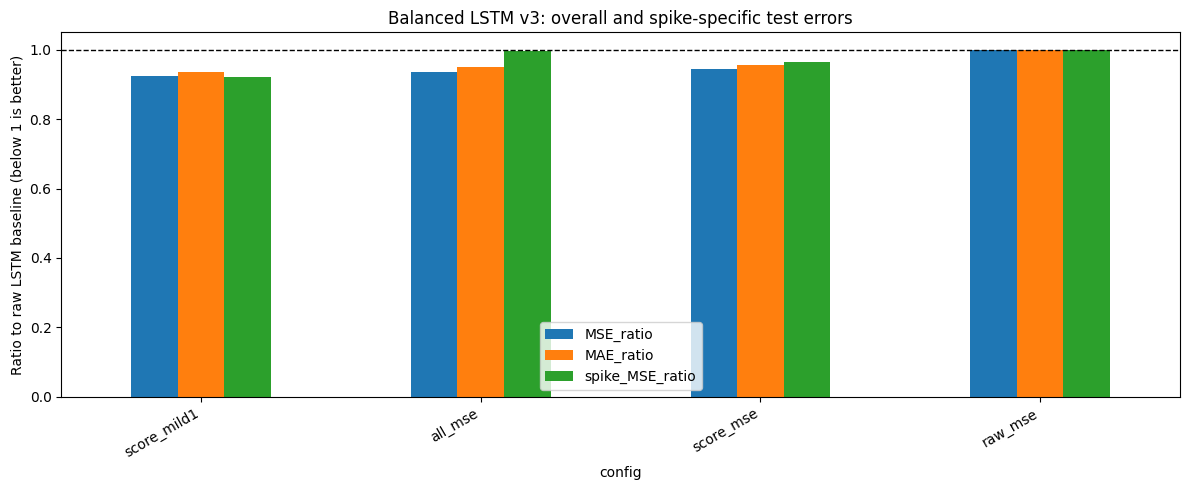

trace,ali20_c,ali20_g,gc11,gc19_a,gc19_b,gc19_c,gc19_d,gc19_e,gc19_f,gc19_g,gc19_h
config,,,,,,,,,,,
all_mse,0.964,1.124,1.170,1.031,0.707,0.982,0.878,0.909,0.415,1.394,0.705
raw_mse,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
score_mild1,0.939,1.206,0.992,0.937,0.674,0.840,0.688,0.990,0.523,1.311,1.053
score_mse,0.991,1.110,1.078,0.874,0.711,0.869,0.774,1.165,0.539,1.192,1.090


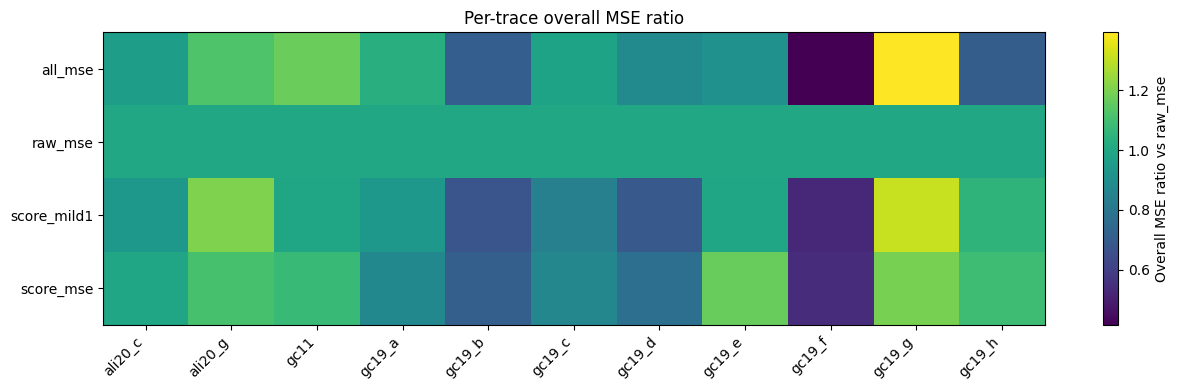

All outputs saved to: /kaggle/working/lstm_v3_balanced


In [9]:
# 9. Visual comparisons
plot_df = paired.groupby("config")[["MSE_ratio", "MAE_ratio", "spike_MSE_ratio"]].mean()
plot_df = plot_df.sort_values("MSE_ratio")
ax = plot_df.plot(kind="bar", figsize=(12, 5))
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Ratio to raw LSTM baseline (below 1 is better)")
ax.set_title("Balanced LSTM v3: overall and spike-specific test errors")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUT / "test_metric_ratios.png", dpi=160)
plt.show()

# Per-trace MSE ratio heatmap, averaged over seeds and resources.
heat = paired.groupby(["config", "trace"])["MSE_ratio"].mean().unstack()
display(heat.round(3))
plt.figure(figsize=(13, max(4, 0.45 * len(heat))))
plt.imshow(heat.values, aspect="auto")
plt.colorbar(label="Overall MSE ratio vs raw_mse")
plt.xticks(range(len(heat.columns)), heat.columns, rotation=45, ha="right")
plt.yticks(range(len(heat.index)), heat.index)
plt.title("Per-trace overall MSE ratio")
plt.tight_layout()
plt.savefig(OUT / "per_trace_mse_heatmap.png", dpi=160)
plt.show()

print("All outputs saved to:", OUT)


## 10. How to decide whether the new LSTM is successful

Use the paired test results, not the best single trace.

A strong balanced improvement should show:
- mean overall MSE ratio < 1,
- mean overall MAE ratio < 1,
- spike MSE and underprediction not materially worse,
- improvement on a substantial fraction of trace/seed/resource pairs, not just one dataset.

If overall MSE/MAE improve but spike metrics worsen, describe the trade-off. If spike metrics improve but overall MSE/MAE worsen, it is a spike-protection model, not a universally more accurate forecaster. If neither improves consistently, retain the previous LSTM as the stronger result and report this experiment as a negative/ablation finding.

**Do not claim success until the final test CSV has been generated and compared.** This notebook has not been executed here; it is a designed experiment, not a result.